# 逻辑回归-客户流失预警系统；

本项目使用逻辑回归算法构建电信客户流失预警模型。

In [1]:
import pandas as pd;
import numpy as np;
import matplotlib.pyplot as plt;
import seaborn as sns;
from sklearn.model_selection import train_test_split;
from sklearn.preprocessing import StandardScaler, LabelEncoder;
from sklearn.linear_model import LogisticRegression;
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
);
import warnings;
warnings.filterwarnings('ignore');

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS'];
plt.rcParams['axes.unicode_minus'] = False;

In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv');

df.columns = df.columns.str.strip();

print(f"数据集形状: {df.shape}");
print(f"\n列名: {df.columns.tolist()}");
print(df[:2]);

数据集形状: (7043, 21)

列名: ['客户ID', '性别', '老年公民', '伴侣', '家属', '在网时长', '电话服务', '多条线路', '互联网服务', '在线安全', '在线备份', '设备保护', '技术支持', '流媒体电视', '流媒体电影', '合同', '无纸化账单', '支付方式', '月费', '总费用', '客户流失']
         客户ID      性别  老年公民   伴侣  家属  在网时长 电话服务              多条线路 互联网服务 在线安全  \
0  7590-VHVEG  Female     0  Yes  No     1   No  No phone service   DSL   No   
1  5575-GNVDE    Male     0   No  No    34  Yes                No   DSL  Yes   

   ... 设备保护 技术支持 流媒体电视 流媒体电影              合同 无纸化账单              支付方式     月费  \
0  ...   No   No    No    No  Month-to-month   Yes  Electronic check  29.85   
1  ...  Yes   No    No    No        One year    No      Mailed check  56.95   

      总费用 客户流失  
0   29.85   No  
1  1889.5   No  

[2 rows x 21 columns]


In [3]:
# 查看数据类型
print("数据类型:");
print(df.dtypes);

数据类型:
客户ID         str
性别           str
老年公民       int64
伴侣           str
家属           str
在网时长       int64
电话服务         str
多条线路         str
互联网服务        str
在线安全         str
在线备份         str
设备保护         str
技术支持         str
流媒体电视        str
流媒体电影        str
合同           str
无纸化账单        str
支付方式         str
月费       float64
总费用          str
客户流失         str
dtype: object


In [4]:
print("缺失值统计:");
print(df.isnull().sum());

缺失值统计:
客户ID     0
性别       0
老年公民     0
伴侣       0
家属       0
在网时长     0
电话服务     0
多条线路     0
互联网服务    0
在线安全     0
在线备份     0
设备保护     0
技术支持     0
流媒体电视    0
流媒体电影    0
合同       0
无纸化账单    0
支付方式     0
月费       0
总费用      0
客户流失     0
dtype: int64


客户流失
No     5174
Yes    1869
Name: count, dtype: int64

流失率: 26.54%


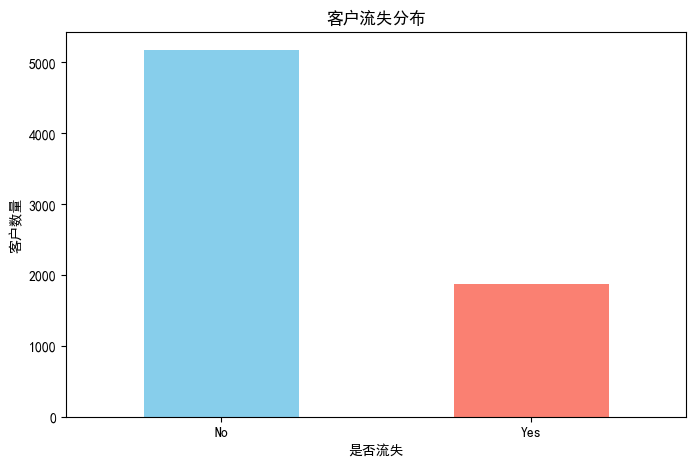

In [5]:
# 查看流失分布。
churn_dist = df['客户流失'].value_counts();
print(churn_dist);
print(f"\n流失率: {churn_dist['Yes'] / len(df) * 100:.2f}%");

# 可视化流失分布。
plt.figure(figsize=(8, 5));
churn_dist.plot(kind='bar', color=['skyblue', 'salmon']);
plt.title('客户流失分布');
plt.xlabel('是否流失');
plt.ylabel('客户数量');
plt.xticks(rotation=0);
plt.show();

In [6]:
# 复制数据。
df_processed = df.copy();

# 删除客户ID列。
df_processed = df_processed.drop('客户ID', axis=1);

# 将总费用转换为数值类型。
df_processed['总费用'] = pd.to_numeric(df_processed['总费用'], errors='coerce');

# 删除包含缺失值的行。
df_processed = df_processed.dropna();
print(f"处理后数据集形状: {df_processed.shape}");

处理后数据集形状: (7032, 20)


In [7]:
# 将目标变量转换为数值。
df_processed['客户流失'] = df_processed['客户流失'].map({'Yes': 1, 'No': 0})

# 获取分类变量。
categorical_cols = df_processed.select_dtypes(include=['object']).columns.tolist();
print(f"分类变量: {categorical_cols}");

分类变量: ['性别', '伴侣', '家属', '电话服务', '多条线路', '互联网服务', '在线安全', '在线备份', '设备保护', '技术支持', '流媒体电视', '流媒体电影', '合同', '无纸化账单', '支付方式']


In [8]:
df_encoded = pd.get_dummies(df_processed, columns=categorical_cols, drop_first=True);
print(f"编码后数据集形状: {df_encoded.shape}");
print(f"特征数量: {df_encoded.shape[1] - 1}");

print(df_encoded[:10]);

编码后数据集形状: (7032, 31)
特征数量: 30
   老年公民  在网时长      月费      总费用  客户流失  性别_Male  伴侣_Yes  家属_Yes  电话服务_Yes  \
0     0     1   29.85    29.85     0    False    True   False     False   
1     0    34   56.95  1889.50     0     True   False   False      True   
2     0     2   53.85   108.15     1     True   False   False      True   
3     0    45   42.30  1840.75     0     True   False   False     False   
4     0     2   70.70   151.65     1    False   False   False      True   
5     0     8   99.65   820.50     1    False   False   False      True   
6     0    22   89.10  1949.40     0     True   False    True      True   
7     0    10   29.75   301.90     0    False   False   False     False   
8     0    28  104.80  3046.05     1    False    True   False      True   
9     0    62   56.15  3487.95     0     True   False    True      True   

   多条线路_No phone service  ...  流媒体电视_No internet service  流媒体电视_Yes  \
0                   True  ...                      False      False   
1 

In [9]:
X = df_encoded.drop('客户流失', axis=1);
y = df_encoded['客户流失'];

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
);

print(f"训练集大小: {X_train.shape[0]}");
print(f"测试集大小: {X_test.shape[0]}");

训练集大小: 5625
测试集大小: 1407


In [10]:
# 特征标准化。
scaler = StandardScaler();
X_train_scaled = scaler.fit_transform(X_train);
X_test_scaled = scaler.transform(X_test);

## 模型训练:

In [11]:
# 创建逻辑回归模型。
model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'  # 处理类别不平衡。
);

In [12]:
# 训练模型。
model.fit(X_train_scaled, y_train);

## 模型评估:

In [13]:
# 预测。
y_pred = model.predict(X_test_scaled);
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1];

# 分类报告。
print("分类报告:");
print(classification_report(y_test, y_pred, target_names=['未流失', '流失']));

分类报告:
              precision    recall  f1-score   support

         未流失       0.91      0.70      0.79      1033
          流失       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [14]:
print("\n评估指标:")
print(f"准确率 (Accuracy): {accuracy_score(y_test, y_pred):.4f}");
print(f"精确率 (Precision): {precision_score(y_test, y_pred):.4f}");
print(f"召回率 (Recall): {recall_score(y_test, y_pred):.4f}");
print(f"F1分数 (F1-Score): {f1_score(y_test, y_pred):.4f}");
print(f"AUC-ROC: {roc_auc_score(y_test, y_pred_proba):.4f}");


评估指标:
准确率 (Accuracy): 0.7264
精确率 (Precision): 0.4909
召回率 (Recall): 0.7968
F1分数 (F1-Score): 0.6075
AUC-ROC: 0.8350



混淆矩阵:


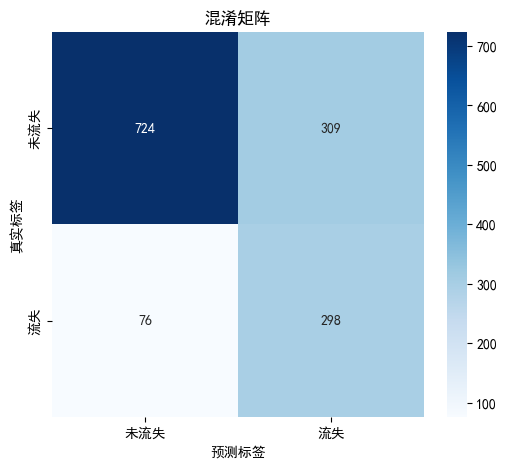

In [15]:
cm = confusion_matrix(y_test, y_pred);
print("\n混淆矩阵:");

plt.figure(figsize=(6, 5));
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['未流失', '流失'],
            yticklabels=['未流失', '流失']);
plt.title('混淆矩阵');
plt.xlabel('预测标签');
plt.ylabel('真实标签');
plt.show();

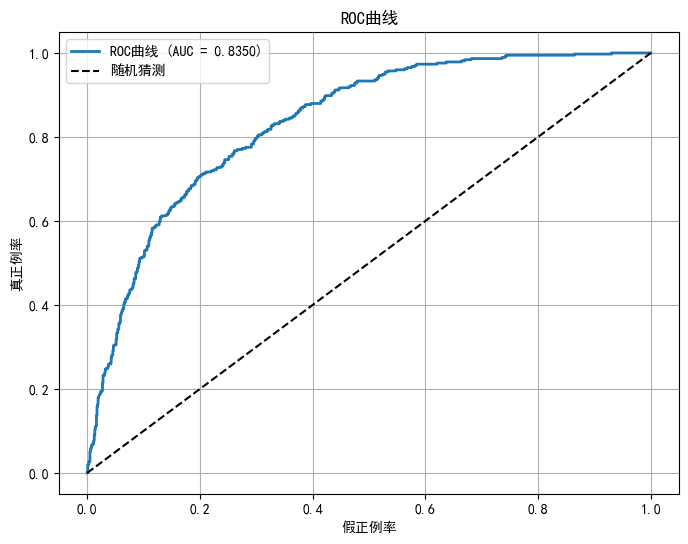

In [16]:
plt.figure(figsize=(8, 6));
fpr, tpr, _ = roc_curve(y_test, y_pred_proba);
plt.plot(fpr, tpr, label=f'ROC曲线 (AUC = {roc_auc_score(y_test, y_pred_proba):.4f})', linewidth=2);
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测');
plt.xlabel('假正例率');
plt.ylabel('真正例率');
plt.title('ROC曲线');
plt.legend();
plt.grid(True);
plt.show();

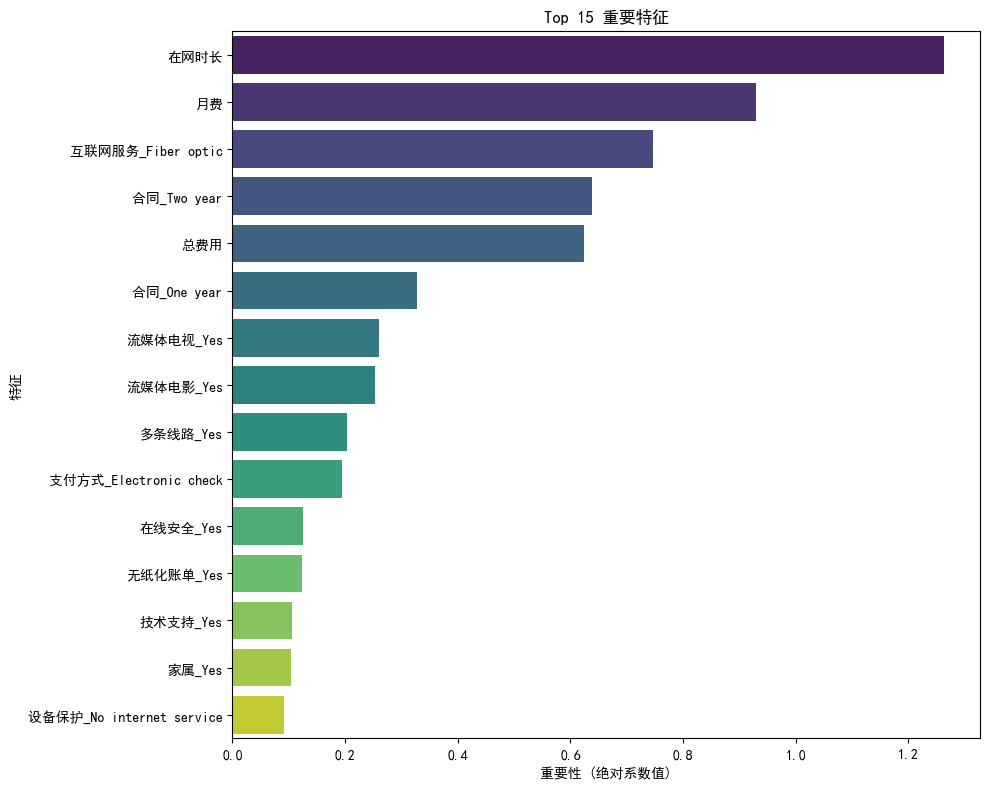

                  feature  importance
1                    在网时长    1.263854
2                      月费    0.928682
10      互联网服务_Fiber optic    0.746144
25            合同_Two year    0.638598
3                     总费用    0.623279
24            合同_One year    0.326693
21              流媒体电视_Yes    0.259691
23              流媒体电影_Yes    0.252870
9                多条线路_Yes    0.202763
28  支付方式_Electronic check    0.193697


In [17]:
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': np.abs(model.coef_[0])
}).sort_values('importance', ascending=False);

plt.figure(figsize=(10, 8));
sns.barplot(data=feature_importance.head(15), y='feature', x='importance', palette='viridis');
plt.title('Top 15 重要特征');
plt.xlabel('重要性 (绝对系数值)');
plt.ylabel('特征');
plt.tight_layout();
plt.show();

print(feature_importance.head(10));

## 8. 客户流失预警示例

In [18]:
def get_risk_level(proba):
    if proba >= 0.7:
        return '高风险';
    elif proba >= 0.4:
        return '中风险';
    else:
        return '低风险';

sample_size = 10;
sample_proba = y_pred_proba[:sample_size];

print("客户流失风险预警示例:");
print("="*50);
for i, proba in enumerate(sample_proba):
    risk = get_risk_level(proba);
    actual = '流失' if y_test.iloc[i] == 1 else '未流失';
    print(f"客户 {i+1}: 流失概率 = {proba:.4f} ({risk}) - 实际: {actual}");

客户流失风险预警示例:
客户 1: 流失概率 = 0.0490 (低风险) - 实际: 未流失
客户 2: 流失概率 = 0.7879 (高风险) - 实际: 未流失
客户 3: 流失概率 = 0.0137 (低风险) - 实际: 未流失
客户 4: 流失概率 = 0.4001 (中风险) - 实际: 流失
客户 5: 流失概率 = 0.2292 (低风险) - 实际: 未流失
客户 6: 流失概率 = 0.7220 (高风险) - 实际: 流失
客户 7: 流失概率 = 0.0728 (低风险) - 实际: 未流失
客户 8: 流失概率 = 0.3474 (低风险) - 实际: 未流失
客户 9: 流失概率 = 0.8493 (高风险) - 实际: 流失
客户 10: 流失概率 = 0.0453 (低风险) - 实际: 未流失



风险等级统计:
  风险等级  客户数量  实际流失数    流失率
0  中风险   343     96  27.99
1  低风险   686     48   7.00
2  高风险   378    230  60.85


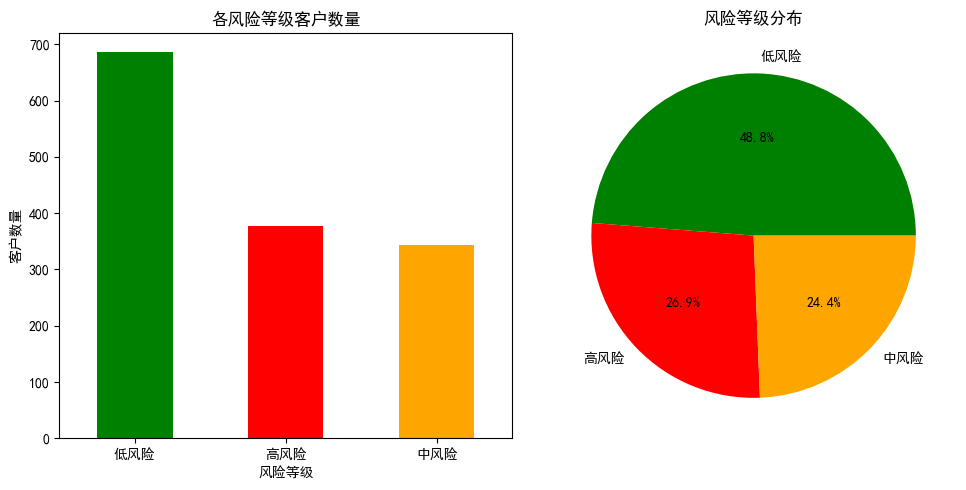

In [19]:
# 统计各风险等级的客户数量。
risk_levels = [get_risk_level(p) for p in y_pred_proba];
risk_df = pd.DataFrame({'risk_level': risk_levels, 'actual': y_test.values});

risk_summary = risk_df.groupby('risk_level').agg({
    'actual': ['count', 'sum']
}).reset_index();
risk_summary.columns = ['风险等级', '客户数量', '实际流失数'];
risk_summary['流失率'] = (risk_summary['实际流失数'] / risk_summary['客户数量'] * 100).round(2);

print("\n风险等级统计:");
print(risk_summary);

plt.figure(figsize=(10, 5));

plt.subplot(1, 2, 1);
risk_counts = risk_df['risk_level'].value_counts();
colors = {'高风险': 'red', '中风险': 'orange', '低风险': 'green'};
risk_counts.plot(kind='bar', color=[colors.get(x, 'blue') for x in risk_counts.index]);
plt.title('各风险等级客户数量');
plt.xlabel('风险等级');
plt.ylabel('客户数量');
plt.xticks(rotation=0);

plt.subplot(1, 2, 2);
plt.pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', 
        colors=[colors.get(x, 'blue') for x in risk_counts.index]);
plt.title('风险等级分布');

plt.tight_layout();
plt.show();

## 模型保存与加载:

In [20]:
import joblib;

# 保存模型。
joblib.dump(model, 'churn_prediction_model.pkl');
joblib.dump(scaler, 'scaler.pkl');

# 加载模型。
# loaded_model = joblib.load('churn_prediction_model.pkl');
# loaded_scaler = joblib.load('scaler.pkl');